# CAPSTONE PROJECT 1
## Working with NumPy Matrices (Multidimensional Data)

### Introduction

This project focuses on analyzing multidimensional body measurement data using Python and its data analysis libraries.

The analysis involves male and female datasets containing various physical measurements, including weight, height, upper arm length, upper leg length, arm circumference, hip circumference, and waist circumference.

Using NumPy, Pandas, Matplotlib, Seaborn, and SciPy, the project explores different statistical methods and visualization techniques to understand patterns, distributions, relationships, and differences within the datasets.

### Objectives

The main objectives of this project are:

- Load, organize, and manipulate multidimensional datasets using NumPy and Pandas.
- Explore weight distributions through histograms, boxplots, and descriptive statistics.
- Calculate BMI and perform Z-score standardization.
- Analyze relationships between different body measurements using correlation techniques.
- Explore Waist-to-Height Ratio (WHtR) and Waist-to-Hip Ratio (WHR).
- Compare measurement patterns using statistical visualizations.
- Identify participants with the lowest and highest BMI values.

### Tools and Technologies

- **Python** – Primary programming language.
- **NumPy** – Multidimensional array operations and numerical computations.
- **Pandas** – Data handling and manipulation.
- **Matplotlib** – Data visualization.
- **Seaborn** – Statistical visualization.
- **SciPy** – Statistical analysis and correlation calculations.

### Project Approach

The project follows a step-by-step analytical approach, beginning with dataset loading and exploration, followed by statistical calculations, data standardization, correlation analysis, and graphical representation of the results.

The aim is to develop practical experience in handling multidimensional data and applying fundamental data analysis techniques using Python.

---

### Analysis

The following sections contain the individual tasks, Python implementations, visualizations, and observations.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Download and load male and female datasets

male_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv"

female_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv"

male = np.genfromtxt(male_url, delimiter=",")[1:, :]

female = np.genfromtxt(female_url, delimiter=",")[1:, :]

print("Male dataset shape:", male.shape)
print("Female dataset shape:", female.shape)

print("\nFirst five male records:")
print(male[:5])

print("\nFirst five female records:")
print(female[:5])

Male dataset shape: (4081, 7)
Female dataset shape: (4221, 7)

First five male records:
[[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]
 [ 99.4 181.6  40.4  39.9  36.  120.2 107. ]]

First five female records:
[[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]
 [ 55.4 154.6  34.6  34.   28.3  92.5  73.2]]


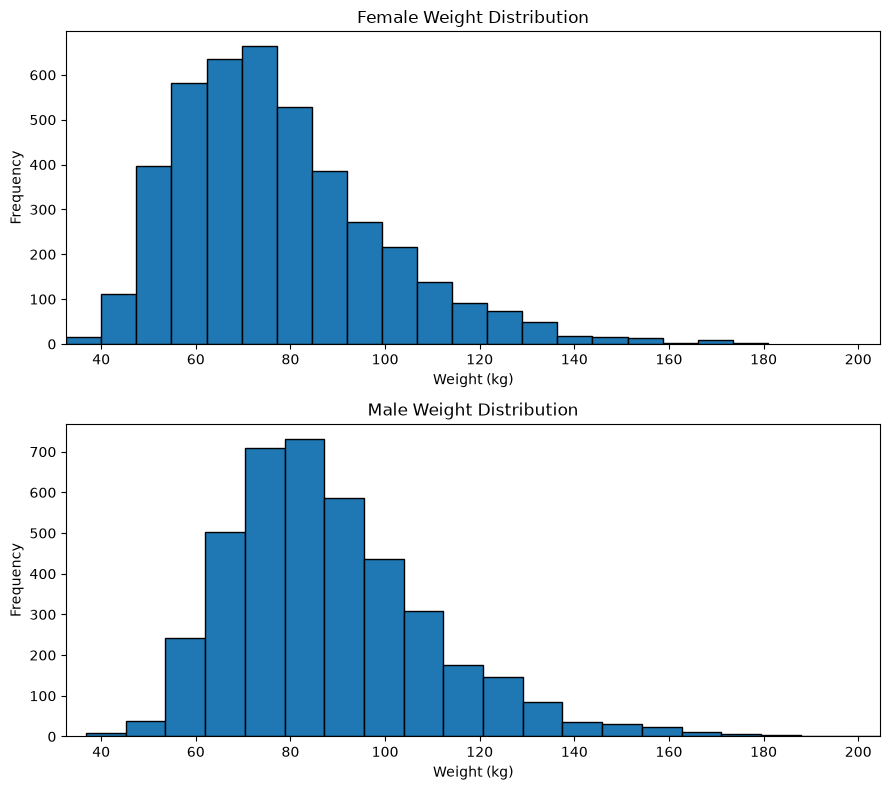

In [4]:
# Task 3: Histograms of female and male weights

female_weights = female[:, 0]
male_weights = male[:, 0]

xmin = min(female_weights.min(), male_weights.min())
xmax = max(female_weights.max(), male_weights.max())

plt.figure(figsize=(9, 8))

plt.subplot(2, 1, 1)
plt.hist(female_weights, bins=20, edgecolor='black')
plt.title("Female Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(xmin, xmax)

plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=20, edgecolor='black')
plt.title("Male Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(xmin, xmax)

plt.tight_layout()
plt.show()

### Interpretation

The histograms show the distribution of body weights among male and female participants. The horizontal axis represents weight in kilograms, while the vertical axis represents the frequency of participants.

The two distributions can be compared to observe differences in their weight ranges, concentration and overall spread.

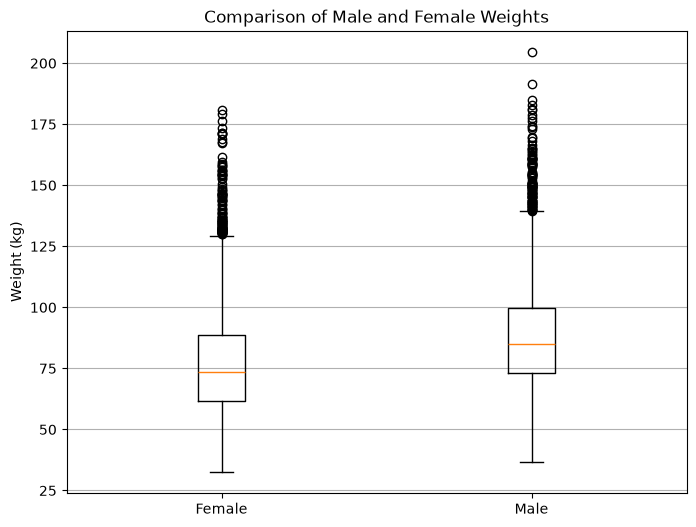

In [5]:
# Task 4: Boxplot comparison of male and female weights

plt.figure(figsize=(8, 6))

plt.boxplot(
    [female_weights, male_weights],
    tick_labels=["Female", "Male"]
)

plt.title("Comparison of Male and Female Weights")
plt.ylabel("Weight (kg)")
plt.grid(axis="y")

plt.show()

### Interpretation

The boxplot compares the weight distributions of male and female participants.

The median line represents the middle weight value of each group. The box represents the middle 50% of the observations, while the whiskers show the spread of the data.

The plot helps identify differences in median weight, variation and possible outliers between males and females.

In [6]:
# Task 5: Numerical aggregates of male and female weights

def weight_statistics(data, gender):

    print("\n", gender, "WEIGHT STATISTICS")
    print("--------------------------------")

    print("Mean:", np.mean(data))
    print("Median:", np.median(data))
    print("Standard Deviation:", np.std(data))
    print("Variance:", np.var(data))
    print("Minimum:", np.min(data))
    print("Maximum:", np.max(data))
    print("Range:", np.ptp(data))
    print("25th Percentile:", np.percentile(data, 25))
    print("75th Percentile:", np.percentile(data, 75))
    print("Skewness:", stats.skew(data))
    print("Kurtosis:", stats.kurtosis(data))


weight_statistics(female_weights, "FEMALE")
weight_statistics(male_weights, "MALE")

print("\nDISPERSION COMPARISON:")

if np.std(female_weights) > np.std(male_weights):
    print("Female weights have greater dispersion.")
else:
    print("Male weights have greater or equal dispersion.")


 FEMALE WEIGHT STATISTICS
--------------------------------
Mean: 77.40379057095475
Median: 73.6
Standard Deviation: 21.54250829019315
Variance: 464.07966343304065
Minimum: 32.6
Maximum: 180.9
Range: 148.3
25th Percentile: 61.6
75th Percentile: 88.7
Skewness: 1.03336107186799
Kurtosis: 1.400968348065974

 MALE WEIGHT STATISTICS
--------------------------------
Mean: 88.36454300416565
Median: 85.0
Standard Deviation: 21.418936717962495
Variance: 458.770850128082
Minimum: 36.8
Maximum: 204.6
Range: 167.8
25th Percentile: 73.3
75th Percentile: 99.8
Skewness: 0.9842810741662346
Kurtosis: 1.4742884754078238

DISPERSION COMPARISON:
Female weights have greater dispersion.


### Interpretation

The statistical measures describe the central tendency, dispersion and shape of the male and female weight distributions.

Mean and median represent the central values, while standard deviation, variance and range indicate the spread of the data.

Skewness describes the symmetry of the distributions. Positive skewness indicates a longer right tail, while negative skewness indicates a longer left tail.

Kurtosis describes the shape of the distribution relative to a normal distribution. These measures help identify differences between male and female weight distributions.

In [7]:
# Task 6: Calculate BMI and add it to female matrix

female_bmi = female[:, 0] / (female[:, 1] / 100) ** 2

female = np.column_stack((female, female_bmi))

print("Female matrix after adding BMI:")
print(female[:5])

print("\nNew female matrix shape:", female.shape)

Female matrix after adding BMI:
[[ 97.1        160.2         34.7         40.8         35.8
  126.1        117.9         37.83504078]
 [ 91.1        152.7         33.5         33.          38.5
  125.5        103.1         39.06972037]
 [ 73.         161.2         37.4         38.          31.8
  106.2         92.          28.09265496]
 [ 61.7        157.4         38.          34.7         29.
  101.          90.5         24.90437849]
 [ 55.4        154.6         34.6         34.          28.3
   92.5         73.2         23.17879132]]

New female matrix shape: (4221, 8)


### Interpretation

The Body Mass Index (BMI) was calculated using the weight and height of each female participant.

The BMI values were added as the eighth column of the female matrix. The resulting matrix contains the original seven body measurements along with the calculated BMI values.

In [8]:
# Task 7: Standardise all columns of female matrix

female_mean = np.mean(female, axis=0)
female_std = np.std(female, axis=0)

zfemale = (female - female_mean) / female_std

print("Standardised female matrix:")
print(zfemale[:5])

print("\nStandardised matrix shape:", zfemale.shape)

Standardised female matrix:
[[ 0.91429508  0.00895038 -0.56739463  1.13298804  0.55084546  1.08316157
   1.11578462  0.9969677 ]
 [ 0.63577599 -1.05306843 -1.07893145 -1.29349161  1.03221804  1.04475528
   0.265089    1.15617483]
 [-0.2044233   0.15055289  0.5835632   0.26194406 -0.1622991  -0.19064688
  -0.37293272 -0.25927501]
 [-0.7289676  -0.38753664  0.83933161 -0.76464348 -0.66150029 -0.52350135
  -0.45915188 -0.67039085]
 [-1.02141265 -0.78402366 -0.6100227  -0.98240447 -0.78630059 -1.06759039
  -1.45354609 -0.89289859]]

Standardised matrix shape: (4221, 8)


### Interpretation

The female dataset was standardised using the Z-score method.

Each measurement was transformed by subtracting its column mean and dividing by its standard deviation.

After standardisation, each column has a mean approximately equal to zero and a standard deviation approximately equal to one.

This makes measurements with different units and scales easier to compare.

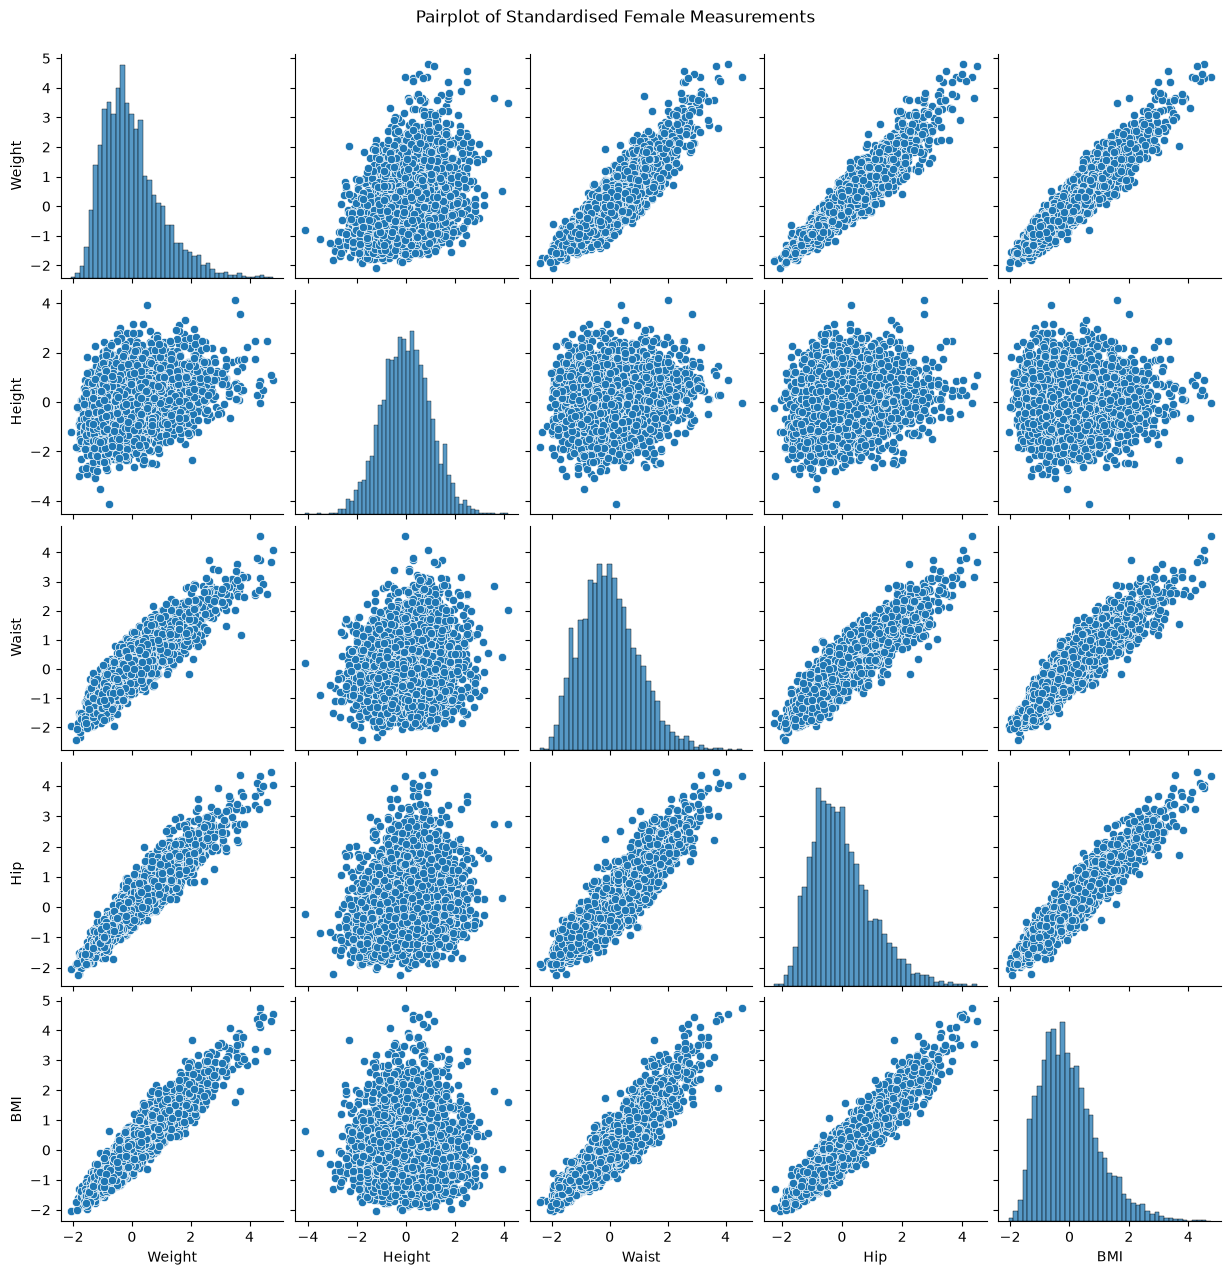

In [9]:
# Task 8: Pairplot of standardised female measurements

selected_data = zfemale[:, [0, 1, 6, 5, 7]]

selected_columns = [
    "Weight", "Height", "Waist", "Hip", "BMI"
]

df = pd.DataFrame(selected_data, columns=selected_columns)

sns.pairplot(df, diag_kind="hist")

plt.suptitle(
    "Pairplot of Standardised Female Measurements",
    y=1.02
)

plt.show()

In [10]:
# Calculate Pearson correlation coefficients

pearson_corr = df.corr(method="pearson")

print("PEARSON CORRELATION MATRIX:")
print(pearson_corr)

# Calculate Spearman correlation coefficients

spearman_corr = df.corr(method="spearman")

print("\nSPEARMAN CORRELATION MATRIX:")
print(spearman_corr)

PEARSON CORRELATION MATRIX:
          Weight    Height     Waist       Hip       BMI
Weight  1.000000  0.345496  0.904550  0.946553  0.945900
Height  0.345496  1.000000  0.126547  0.202895  0.033077
Waist   0.904550  0.126547  1.000000  0.897407  0.921198
Hip     0.946553  0.202895  0.897407  1.000000  0.944199
BMI     0.945900  0.033077  0.921198  0.944199  1.000000

SPEARMAN CORRELATION MATRIX:
          Weight    Height     Waist       Hip       BMI
Weight  1.000000  0.338860  0.900169  0.946634  0.937999
Height  0.338860  1.000000  0.108587  0.205405  0.019897
Waist   0.900169  0.108587  1.000000  0.888037  0.923114
Hip     0.946634  0.205405  0.888037  1.000000  0.934196
BMI     0.937999  0.019897  0.923114  0.934196  1.000000


### Interpretation

The pairplot illustrates the relationships between weight, height, waist circumference, hip circumference and BMI among female participants.

Pearson's correlation measures the strength and direction of linear relationships, while Spearman's correlation measures the strength and direction of monotonic relationships.

Correlation coefficients close to +1 indicate strong positive relationships, while values close to -1 indicate strong negative relationships. Values near zero indicate weak relationships.

The correlation matrices help identify which body measurements are most strongly associated with one another.

In [11]:
# Task 9: Calculate waist-to-height and waist-to-hip ratios

# Male ratios
male_wht = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]

# Female ratios
female_wht = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]

# Add ratios to male and female matrices
male = np.column_stack((male, male_wht, male_whr))

female = np.column_stack((female, female_wht, female_whr))

print("Male matrix after adding ratios:")
print(male[:5])

print("\nFemale matrix after adding ratios:")
print(female[:5])

print("\nMale matrix shape:", male.shape)
print("Female matrix shape:", female.shape)

Male matrix after adding ratios:
[[ 98.8        182.3         42.          40.1         38.2
  108.2        120.4          0.66044981   1.11275416]
 [ 74.3        184.2         41.1         41.          30.2
   94.5         86.8          0.47122693   0.91851852]
 [103.7        185.3         47.          44.          32.
  107.8        109.6          0.59147329   1.01669759]
 [ 86.         167.8         39.5         38.4         29.
  106.4        108.3          0.6454112    1.01785714]
 [ 99.4        181.6         40.4         39.9         36.
  120.2        107.           0.58920705   0.89018303]]

Female matrix after adding ratios:
[[ 97.1        160.2         34.7         40.8         35.8
  126.1        117.9         37.83504078   0.73595506   0.93497224]
 [ 91.1        152.7         33.5         33.          38.5
  125.5        103.1         39.06972037   0.67518009   0.82151394]
 [ 73.         161.2         37.4         38.          31.8
  106.2         92.          28.09265496  

### Interpretation

The waist-to-height ratio and waist-to-hip ratio were calculated for both male and female participants.

These ratios were added as two additional columns to their respective matrices.

The resulting matrices contain the original body measurements, BMI for females, and the two calculated body measurement ratios.

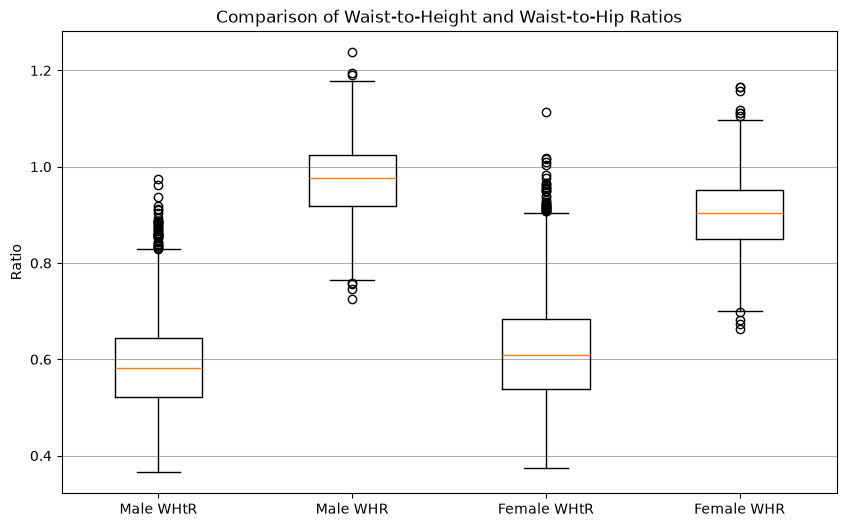

In [12]:
# Task 10: Boxplot comparison of four body measurement ratios

plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        male[:, 7],
        male[:, 8],
        female[:, 8],
        female[:, 9]
    ],
    tick_labels=[
        "Male WHtR",
        "Male WHR",
        "Female WHtR",
        "Female WHR"
    ]
)

plt.title("Comparison of Waist-to-Height and Waist-to-Hip Ratios")
plt.ylabel("Ratio")
plt.grid(axis="y")

plt.show()

### Interpretation

The boxplot compares the waist-to-height and waist-to-hip ratios of male and female participants.

The median lines represent the central values of each distribution, while the boxes indicate the middle 50% of observations.

The differences in median values, spread and outliers help describe variations in body measurement ratios between the two groups.

## Task 11: Advantages and Disadvantages of Body Measurement Indicators

### 1. Body Mass Index (BMI)

**Advantages:**
- Easy to calculate using height and weight.
- Useful for population-level health studies.
- Requires only two measurements.

**Disadvantages:**
- Does not directly measure body fat.
- Cannot distinguish muscle mass from fat mass.
- Does not indicate where fat is distributed.

### 2. Waist-to-Height Ratio (WHtR)

**Advantages:**
- Considers waist circumference relative to height.
- Provides information about abdominal fat distribution.
- Simple to calculate and interpret.

**Disadvantages:**
- Requires accurate waist and height measurements.
- Does not directly measure body composition.
- May not be equally suitable for every population.

### 3. Waist-to-Hip Ratio (WHR)

**Advantages:**
- Shows the relationship between waist and hip measurements.
- Helps describe body fat distribution.
- Easy to calculate.

**Disadvantages:**
- Requires two circumference measurements.
- Results can vary depending on measurement technique.
- Does not directly measure total body fat.

In [13]:
# Task 12: Identify participants with lowest and highest BMI

# Extract female BMI values
bmi_values = female[:, 7]

# Sort BMI values using argsort
sorted_indices = np.argsort(bmi_values)

# Find five lowest and five highest BMI participants
lowest_bmi_indices = sorted_indices[:5]
highest_bmi_indices = sorted_indices[-5:][::-1]

print("FIVE PARTICIPANTS WITH LOWEST BMI:")

print("\nBMI values:")
print(bmi_values[lowest_bmi_indices])

print("\nStandardised body measurements:")
print(zfemale[lowest_bmi_indices])


print("\n\nFIVE PARTICIPANTS WITH HIGHEST BMI:")

print("\nBMI values:")
print(bmi_values[highest_bmi_indices])

print("\nStandardised body measurements:")
print(zfemale[highest_bmi_indices])

FIVE PARTICIPANTS WITH LOWEST BMI:

BMI values:
[14.20340054 14.63273036 14.81882399 15.04456103 15.42130871]

Standardised body measurements:
[[-2.07978523 -1.22299143 -1.5478402  -1.16905675 -2.1947611  -2.0405496
  -1.94212128 -2.05024028]
 [-1.88017988 -0.18929313 -1.71835247  0.38637892 -2.4443617  -1.85491922
  -2.05708015 -1.99487987]
 [-1.53667299  1.80730222  0.62619127  0.5730312  -2.26607556 -1.6756899
  -1.7064556  -1.97088383]
 [-1.843044   -0.26009438 -0.22637009  0.51081377 -2.30173278 -2.25178417
  -1.85590213 -1.94177591]
 [-1.61094475  0.88688592 -0.09848588  0.47970506 -2.21258971 -1.82931504
  -1.71220354 -1.89319577]]


FIVE PARTICIPANTS WITH HIGHEST BMI:

BMI values:
[67.03689493 65.33289802 65.11544005 64.7070699  64.19895366]

Standardised body measurements:
[[ 4.36328993 -0.03353037 -0.05585782 -0.17357792  2.77942222  4.31569054
   4.57029862  4.76243308]
 [ 4.8042785   0.88688592  2.11817365  1.81737973  3.77782461  4.02124236
   4.08172343  4.54270932]
 [ 4.

### Interpretation

The five participants with the lowest BMI and the five participants with the highest BMI were identified using NumPy's argsort() function.

Their standardised body measurements were displayed using the zfemale matrix.

Positive Z-scores indicate measurements above the dataset mean, while negative Z-scores indicate measurements below the dataset mean.

The results demonstrate how BMI relates to other body measurements, including waist circumference, hip circumference and height.

# Conclusion

This project explored multidimensional body measurement data using NumPy, Pandas, Matplotlib and statistical methods.

Male and female weight distributions were compared using histograms, boxplots and numerical statistical measures.

BMI was calculated for female participants, and the dataset was standardised using Z-scores. Pairplots and correlation coefficients were used to examine relationships between different body measurements.

Waist-to-height and waist-to-hip ratios were also calculated and compared between male and female participants.

Finally, participants with the lowest and highest BMI values were identified using NumPy.

Overall, this project demonstrated the usefulness of Python libraries in numerical data analysis, statistical comparison and visualisation.